In [ ]:
# Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Load dataset
df = pd.read_csv("/content/train (6).csv")   # change path if needed

# -----------------------------
# DATA PREPROCESSING
# -----------------------------

# Convert categorical columns to numeric
categorical_cols = ['protocol_type', 'service', 'flag']

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Convert target label to binary (Normal = 0, Attack = 1)
# Assuming the target column is named 'class' instead of 'label'
df['class'] = df['class'].apply(lambda x: 0 if x == 'normal' else 1)

# Split features and target
X = df.drop('class', axis=1)
y = df['class']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -----------------------------
# MODEL 1: Logistic Regression
# -----------------------------
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


# -----------------------------
# MODEL 2: Random Forest
# -----------------------------
rf = RandomForestClassifier(n_estimators=100)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("\n=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))


# -----------------------------
# MODEL 3: KNN
# -----------------------------
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("\n=== KNN ===")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

=== Logistic Regression ===
Accuracy: 0.9536599080474978
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     16050
           1       0.96      0.94      0.95     14183

    accuracy                           0.95     30233
   macro avg       0.95      0.95      0.95     30233
weighted avg       0.95      0.95      0.95     30233


=== Random Forest ===
Accuracy: 0.9993715476466113
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16050
           1       1.00      1.00      1.00     14183

    accuracy                           1.00     30233
   macro avg       1.00      1.00      1.00     30233
weighted avg       1.00      1.00      1.00     30233


=== KNN ===
Accuracy: 0.9967915853537526
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16050
           1       1.00      1.00      1.00     14183

    accuracy                   

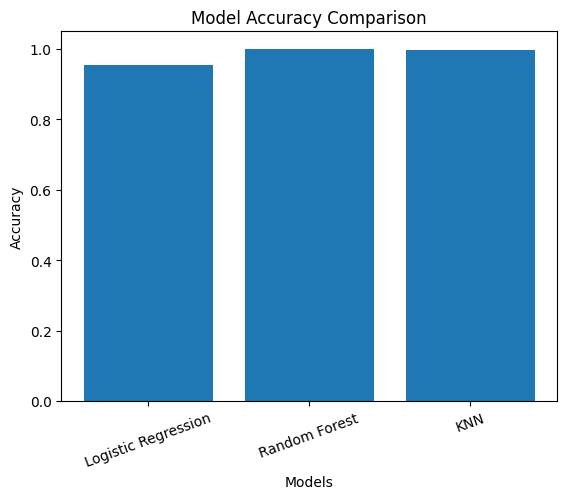

In [ ]:
import matplotlib.pyplot as plt

# Store accuracies
models = ['Logistic Regression', 'Random Forest', 'KNN']
accuracies = [
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_knn)
]

plt.figure()
plt.bar(models, accuracies)
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)

plt.show()

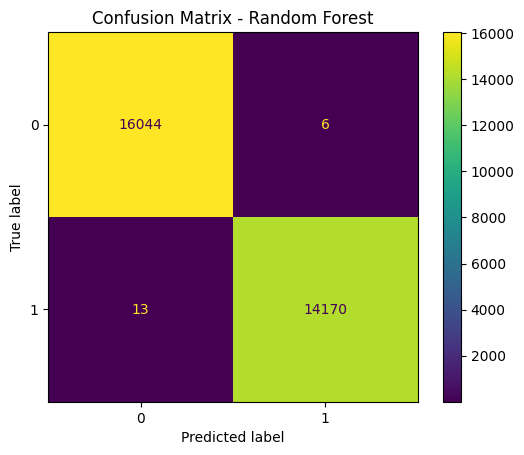

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix - Random Forest")
plt.show()

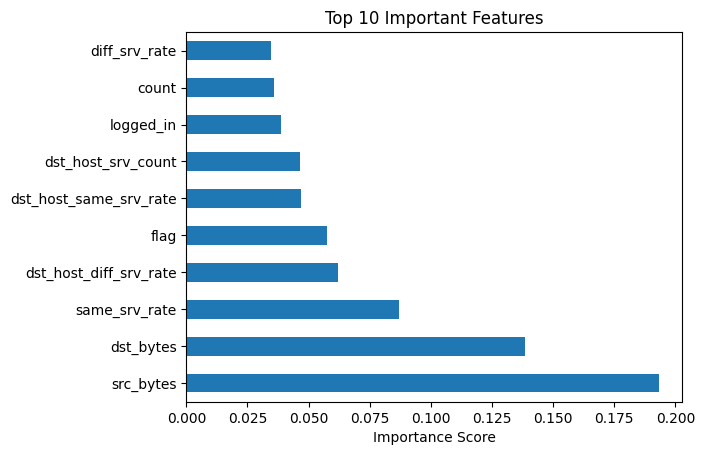

In [ ]:
import pandas as pd

importances = rf.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)
feat_imp.nlargest(10).plot(kind='barh')

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.show()

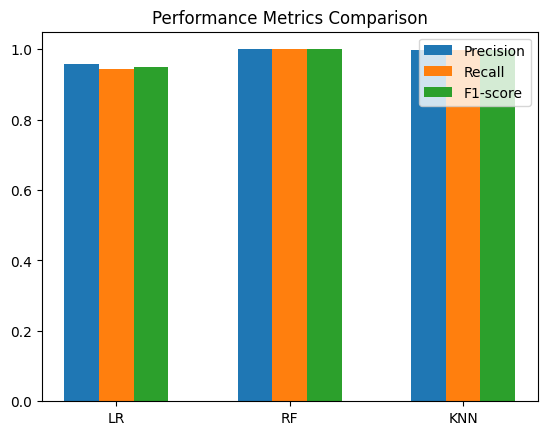

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = [
    precision_score(y_test, y_pred_lr),
    precision_score(y_test, y_pred_rf),
    precision_score(y_test, y_pred_knn)
]

recall = [
    recall_score(y_test, y_pred_lr),
    recall_score(y_test, y_pred_rf),
    recall_score(y_test, y_pred_knn)
]

f1 = [
    f1_score(y_test, y_pred_lr),
    f1_score(y_test, y_pred_rf),
    f1_score(y_test, y_pred_knn)
]

x = range(3)

plt.figure()
plt.bar(x, precision, width=0.2, label='Precision')
plt.bar([i + 0.2 for i in x], recall, width=0.2, label='Recall')
plt.bar([i + 0.4 for i in x], f1, width=0.2, label='F1-score')

plt.xticks([i + 0.2 for i in x], ['LR', 'RF', 'KNN'])
plt.title("Performance Metrics Comparison")
plt.legend()

plt.show()

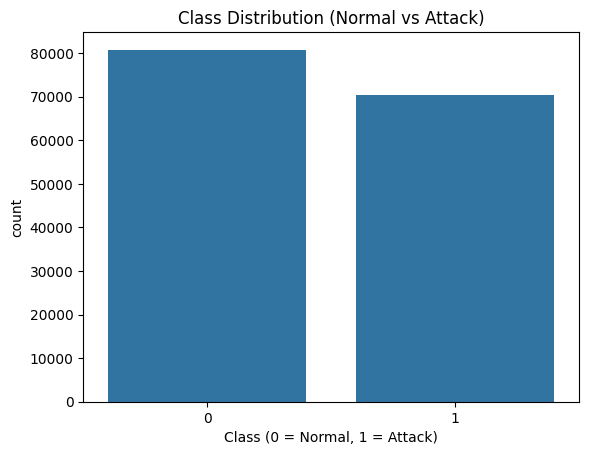

In [ ]:
import seaborn as sns

sns.countplot(x=y)
plt.title("Class Distribution (Normal vs Attack)")
plt.xlabel("Class (0 = Normal, 1 = Attack)")
plt.show()